# Lab 7: Color Image Processing

**Student Name:** Mujtaba Alnuwaysir
**University ID:** 2240007941

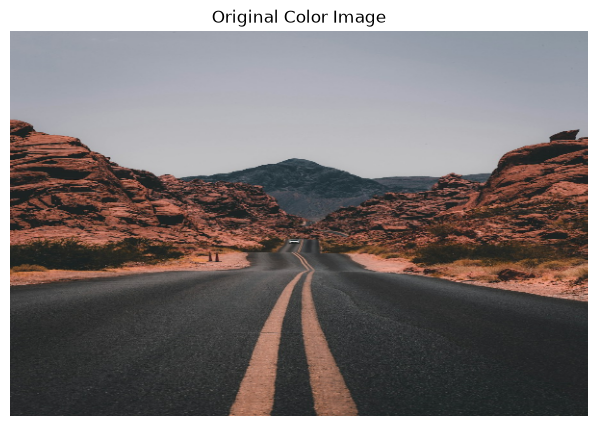

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from urllib.request import urlopen

# Download a color image directly from the internet
image_url = "https://images.unsplash.com/photo-1500530855697-b586d89ba3ee?w=900&auto=format&fit=crop&q=85"

image_data = urlopen(image_url, timeout=30).read()
image_array = np.frombuffer(image_data, dtype=np.uint8)

# Read the image in color
img_bgr = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

if img_bgr is None:
    raise ValueError("Could not load the image.")

# Resize the image
img_bgr = cv2.resize(img_bgr, (600, 400))

# Convert BGR to RGB for correct display
img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# Display the original color image
plt.figure(figsize=(8, 5))
plt.imshow(img)
plt.title("Original Color Image")
plt.axis("off")
plt.show()

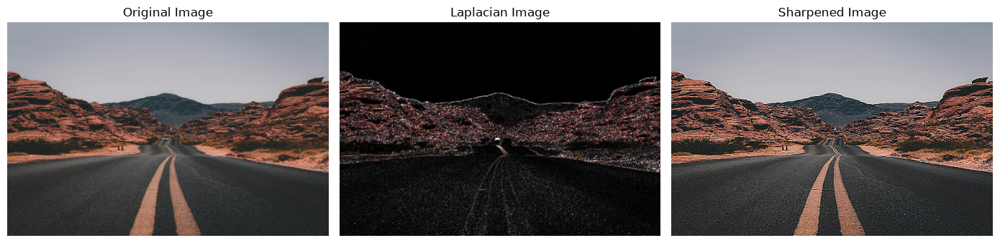

In [3]:
# Define the Laplacian kernel
laplacian_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# Apply the filter to each color channel
laplacian_channels = []

for channel in cv2.split(img):
    lap = cv2.filter2D(
        channel, cv2.CV_64F, laplacian_kernel
    )
    laplacian_channels.append(lap)

# Combine the filtered channels
laplacian = cv2.merge(laplacian_channels)

# Convert the Laplacian result for display
laplacian_display = np.clip(
    np.abs(laplacian), 0, 255
).astype(np.uint8)

# Sharpen the original color image
sharp_float = img.astype(np.float32) - laplacian
sharp_img = np.clip(
    sharp_float, 0, 255
).astype(np.uint8)

# Display results
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(laplacian_display)
plt.title("Laplacian Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sharp_img)
plt.title("Sharpened Image")
plt.axis("off")

plt.tight_layout()
plt.show()

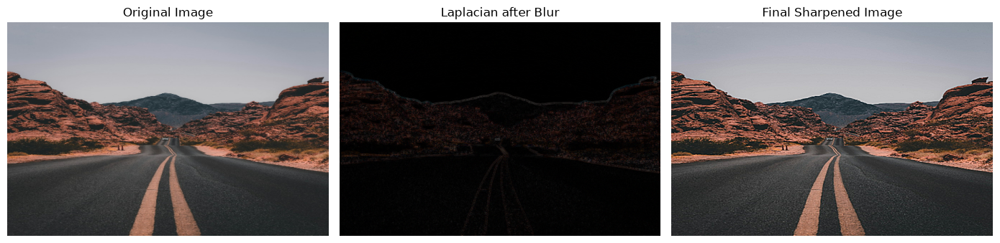

In [4]:
# Apply Gaussian blur to reduce small noise
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# Apply Laplacian to each color channel
laplacian_channels = []

for channel in cv2.split(blurred):
    lap = cv2.Laplacian(channel, cv2.CV_64F)
    laplacian_channels.append(lap)

laplacian = cv2.merge(laplacian_channels)

# Convert the result to an 8-bit image
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# Create a sharper image
final_image = np.clip(
    img.astype(np.int16) - laplacian.astype(np.int16),
    0, 255
).astype(np.uint8)

# Display the results
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(laplacian_8bit)
plt.title("Laplacian after Blur")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(final_image)
plt.title("Final Sharpened Image")
plt.axis("off")

plt.tight_layout()
plt.show()

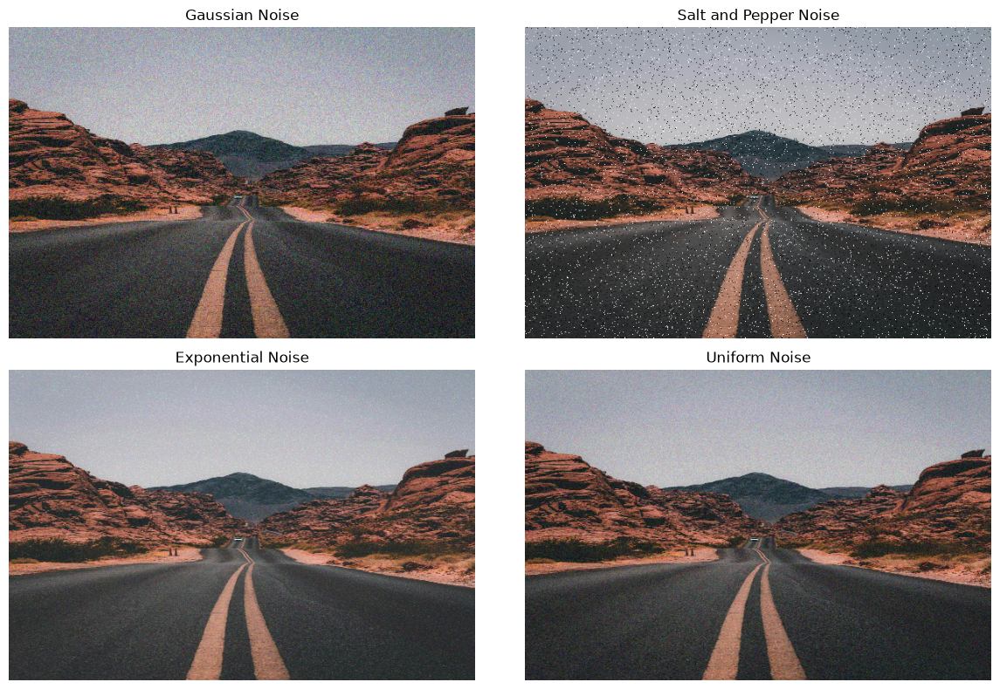

In [5]:
# Function to add noise to a color image
def add_noise_color(image, noise_type):
    image_float = image.astype(np.float32)

    if noise_type == "gaussian":
        noise = np.random.normal(
            0, 18, image.shape
        )
        noisy = image_float + noise

    elif noise_type == "salt_pepper":
        noisy = image.copy()
        amount = 0.04

        # Generate random pixel positions
        random_map = np.random.random(image.shape[:2])

        # Add black pixels
        noisy[random_map < amount / 2] = [0, 0, 0]

        # Add white pixels
        noisy[random_map > 1 - amount / 2] = [255, 255, 255]

        return noisy

    elif noise_type == "exponential":
        noise = np.random.exponential(
            scale=8, size=image.shape
        )
        noisy = image_float + noise

    elif noise_type == "uniform":
        noise = np.random.uniform(
            -20, 20, image.shape
        )
        noisy = image_float + noise

    else:
        raise ValueError("Unknown noise type")

    return np.clip(noisy, 0, 255).astype(np.uint8)


# Generate noisy color images
noise_gauss = add_noise_color(img, "gaussian")
noise_sp = add_noise_color(img, "salt_pepper")
noise_expo = add_noise_color(img, "exponential")
noise_uni = add_noise_color(img, "uniform")

# Display all noisy images
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(noise_gauss)
plt.title("Gaussian Noise")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(noise_sp)
plt.title("Salt and Pepper Noise")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(noise_expo)
plt.title("Exponential Noise")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(noise_uni)
plt.title("Uniform Noise")
plt.axis("off")

plt.tight_layout()
plt.show()

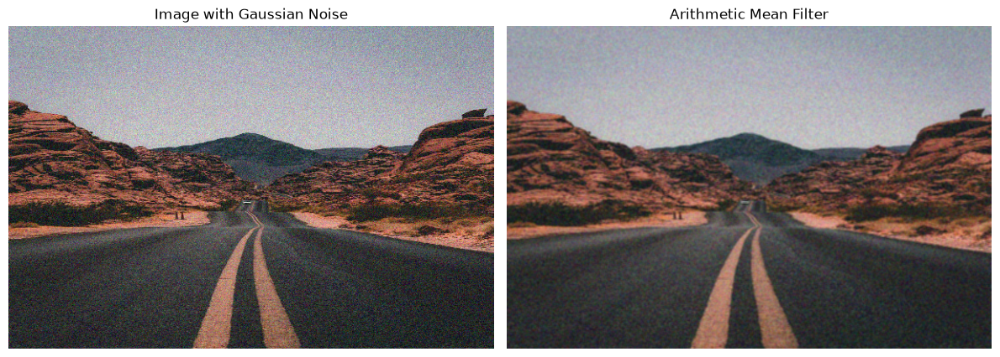

In [6]:
# Apply the Arithmetic Mean Filter
mean_filtered = cv2.blur(noise_gauss, (3, 3))

# Display the results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(noise_gauss)
plt.title("Image with Gaussian Noise")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mean_filtered)
plt.title("Arithmetic Mean Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

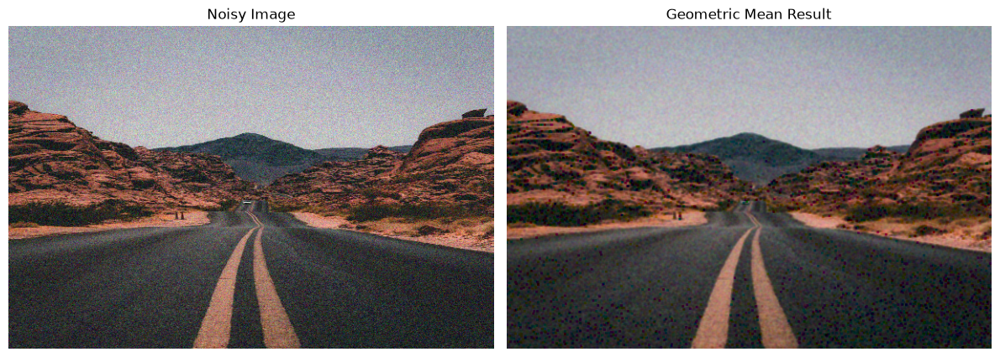

In [7]:
def geometric_mean_filter(image, kernel_size=3):
    channels = []

    # Create the averaging kernel
    kernel = np.ones(
        (kernel_size, kernel_size), np.float32
    ) / (kernel_size * kernel_size)

    for channel in cv2.split(image):
        # Avoid log of zero
        values = channel.astype(np.float64) + 1e-6

        # Calculate the average of logarithms
        log_image = np.log(values)
        mean_log = cv2.filter2D(log_image, -1, kernel)

        # Convert back using exponential
        result = np.exp(mean_log)

        channels.append(
            np.clip(result, 0, 255).astype(np.uint8)
        )

    return cv2.merge(channels)


# Apply the filter
geometric_result = geometric_mean_filter(
    noise_gauss, kernel_size=3
)

# Display the results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(noise_gauss)
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(geometric_result)
plt.title("Geometric Mean Result")
plt.axis("off")

plt.tight_layout()
plt.show()

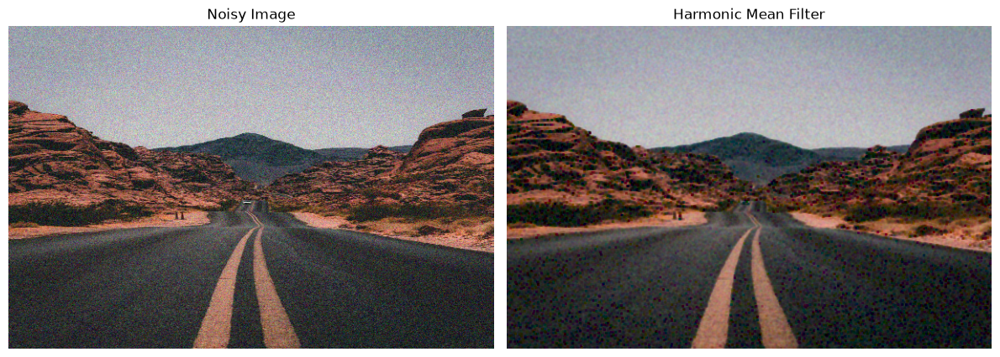

In [8]:
def harmonic_mean_filter(image, kernel_size=3):
    channels = []
    kernel = np.ones(
        (kernel_size, kernel_size), np.float32
    )

    n = kernel_size * kernel_size

    for channel in cv2.split(image):
        values = channel.astype(np.float64) + 1e-6

        # Calculate the reciprocal
        reciprocal = 1.0 / values

        # Sum reciprocal values in the window
        reciprocal_sum = cv2.filter2D(
            reciprocal, -1, kernel
        )

        # Calculate the harmonic mean
        result = n / reciprocal_sum

        channels.append(
            np.clip(result, 0, 255).astype(np.uint8)
        )

    return cv2.merge(channels)


# Apply the filter
harmonic_result = harmonic_mean_filter(
    noise_gauss, kernel_size=3
)

# Display the results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(noise_gauss)
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(harmonic_result)
plt.title("Harmonic Mean Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

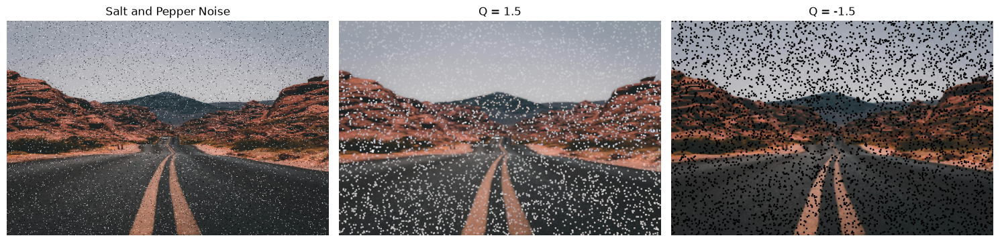

In [9]:
def contra_harmonic_mean(image, kernel_size=3, Q=1.5):
    channels = []

    kernel = np.ones(
        (kernel_size, kernel_size), np.float64
    )

    for channel in cv2.split(image):
        values = channel.astype(np.float64) + 1e-6

        # Calculate the numerator
        numerator = cv2.filter2D(
            np.power(values, Q + 1), -1, kernel
        )

        # Calculate the denominator
        denominator = cv2.filter2D(
            np.power(values, Q), -1, kernel
        )

        # Calculate the result
        result = numerator / (denominator + 1e-6)

        channels.append(
            np.clip(result, 0, 255).astype(np.uint8)
        )

    return cv2.merge(channels)


# Apply the filter with positive and negative Q
pepper_removed = contra_harmonic_mean(
    noise_sp, kernel_size=3, Q=1.5
)

salt_removed = contra_harmonic_mean(
    noise_sp, kernel_size=3, Q=-1.5
)

# Display the results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(noise_sp)
plt.title("Salt and Pepper Noise")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(pepper_removed)
plt.title("Q = 1.5")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(salt_removed)
plt.title("Q = -1.5")
plt.axis("off")

plt.tight_layout()
plt.show()

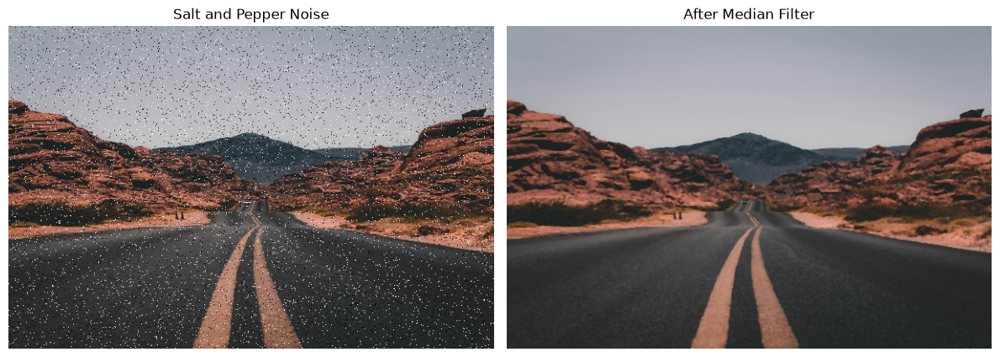

In [10]:
# Apply the Median Filter
median_result = cv2.medianBlur(noise_sp, 3)

# Display the results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(noise_sp)
plt.title("Salt and Pepper Noise")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(median_result)
plt.title("After Median Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

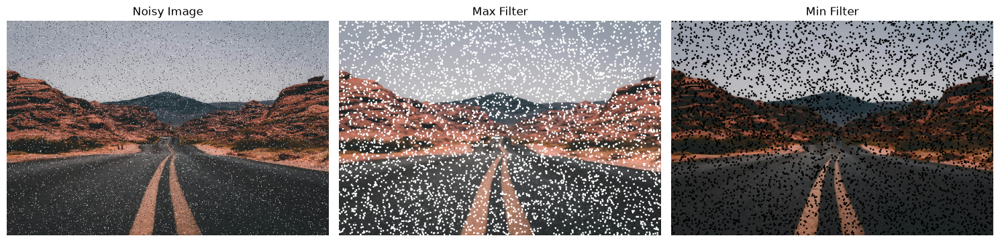

In [11]:
# Define a 3x3 kernel
kernel = np.ones((3, 3), np.uint8)

# Apply the Max Filter
max_channels = [
    cv2.dilate(channel, kernel)
    for channel in cv2.split(noise_sp)
]
max_result = cv2.merge(max_channels)

# Apply the Min Filter
min_channels = [
    cv2.erode(channel, kernel)
    for channel in cv2.split(noise_sp)
]
min_result = cv2.merge(min_channels)

# Display the results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(noise_sp)
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(max_result)
plt.title("Max Filter")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(min_result)
plt.title("Min Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

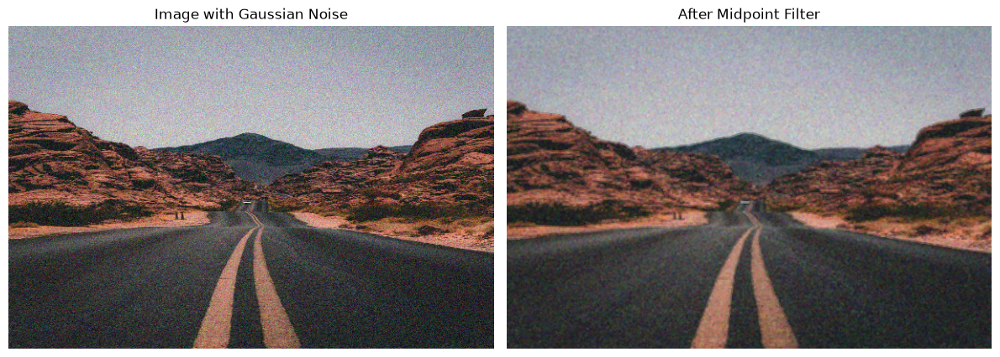

In [12]:
def midpoint_filter(image, kernel_size=3):
    kernel = np.ones(
        (kernel_size, kernel_size), np.uint8
    )

    channels = []

    for channel in cv2.split(image):
        # Find the maximum value
        max_image = cv2.dilate(channel, kernel).astype(
            np.float32
        )

        # Find the minimum value
        min_image = cv2.erode(channel, kernel).astype(
            np.float32
        )

        # Calculate the midpoint
        midpoint = (max_image + min_image) / 2

        channels.append(
            np.clip(midpoint, 0, 255).astype(np.uint8)
        )

    return cv2.merge(channels)


# Apply the Midpoint Filter
midpoint_result = midpoint_filter(
    noise_gauss, kernel_size=3
)

# Display the results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(noise_gauss)
plt.title("Image with Gaussian Noise")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(midpoint_result)
plt.title("After Midpoint Filter")
plt.axis("off")

plt.tight_layout()
plt.show()